In [1]:
# Cellule 1 : imports et detection automatique des chemins
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Colab : remplace par P = '/content/' et IMG = '/content/images/'
hits = glob.glob('/kaggle/input/**/train.tsv', recursive=True)
assert hits, 'train.tsv introuvable : ajoute ton dataset avec Add Input'
if len(hits) > 1:
    print('ATTENTION : plusieurs train.tsv trouves, le premier est utilise :', hits)
P = os.path.dirname(hits[0]) + '/'
IMG = P + 'images/images/' if os.path.isdir(P + 'images/images') else P + 'images/'
print('P   =', P)
print('IMG =', IMG)
OUT = '/kaggle/working/'
os.makedirs(OUT + 'results', exist_ok=True)
os.makedirs(OUT + 'figures', exist_ok=True)

P   = /kaggle/input/datasets/sahnounsahnoun/data-fakenewes/
IMG = /kaggle/input/datasets/sahnounsahnoun/data-fakenewes/images/images/


In [2]:
# Cellule 2 : chargement, controle de version du dataset et d'integrite (on veut 0 image manquante)
tr, va, te = [pd.read_csv(P + s + '.tsv', sep='\t') for s in ['train', 'val', 'test']]

# version NETTOYEE du dataset (celle de E1, E2, E3 : test = 1 396 publications)
VERIFIER_TAILLES = True
ATTENDU = {'train': 7432, 'val': 1403, 'test': 1396}
for name, d in [('train', tr), ('val', va), ('test', te)]:
    print(name, len(d), 'exemples (attendu :', ATTENDU[name], ')')
    if VERIFIER_TAILLES:
        assert len(d) == ATTENDU[name], (
            '%s : %d publications, %d attendues. Ce n est pas la version nettoyee du dataset '
            '(l ancienne version non nettoyee a 7792 / 1469 / 1450). Retire l ancien dataset des Inputs '
            'et ajoute la version nettoyee.' % (name, len(d), ATTENDU[name]))

have = {f[:-4] for f in os.listdir(IMG)}
print(len(have), 'images dans le dossier |', len(tr) + len(va) + len(te), 'posts dans les splits (attendu : 10231)')
for name, d in [('train', tr), ('val', va), ('test', te)]:
    missing = (~d['id'].astype(str).isin(have)).sum()
    print(name, '| images manquantes :', missing)

train 7432 exemples (attendu : 7432 )
val 1403 exemples (attendu : 1403 )
test 1396 exemples (attendu : 1396 )
10711 images dans le dossier | 10231 posts dans les splits (attendu : 10231)
train | images manquantes : 0
val | images manquantes : 0
test | images manquantes : 0


train 7432 {0: 0.503, 1: 0.497}
   6-way : {0: 3697, 1: 367, 2: 1106, 3: 137, 4: 1856, 5: 269}
val 1403 {0: 0.502, 1: 0.498}
   6-way : {0: 698, 1: 66, 2: 231, 3: 25, 4: 346, 5: 37}
test 1396 {1: 0.503, 0: 0.497}
   6-way : {0: 702, 1: 63, 2: 212, 3: 21, 4: 347, 5: 51}
              count  mean  std  min  25%  50%   75%   max
2_way_label                                              
0            3735.0   6.1  5.1  1.0  2.0  5.0   8.0  51.0
1            3697.0   9.4  5.5  1.0  6.0  9.0  12.0  56.0


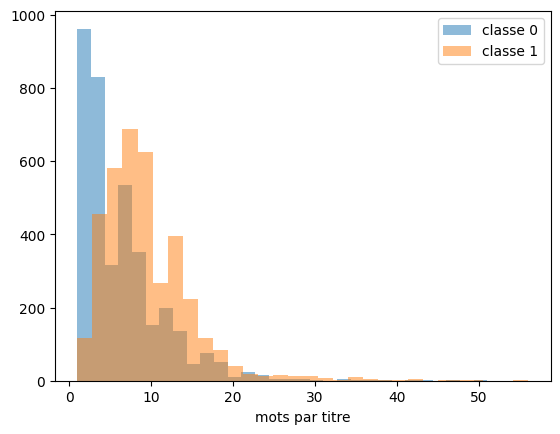

mots par titre, moyenne sur le train (classe 0 = faux, classe 1 = vrai) : {0: 6.1, 1: 9.4}
part de la classe 1 dans le test : 0.503 = accuracy du modele "tout vrai"


In [3]:
# Cellule 3 : equilibre des classes et longueur des titres
for name, d in [('train', tr), ('val', va), ('test', te)]:
    print(name, len(d), d['2_way_label'].value_counts(normalize=True).round(3).to_dict())
    print('   6-way :', d['6_way_label'].value_counts().sort_index().to_dict())

tr['n_words'] = tr['clean_title'].str.split().str.len()
print(tr.groupby('2_way_label')['n_words'].describe().round(1))
for lab in [0, 1]:
    plt.hist(tr.loc[tr['2_way_label'] == lab, 'n_words'], bins=30, alpha=0.5, label='classe ' + str(lab))
plt.xlabel('mots par titre'); plt.legend()
plt.savefig(OUT + 'figures/eda_longueur_titres.png', dpi=150, bbox_inches='tight')
plt.show()
print('mots par titre, moyenne sur le train (classe 0 = faux, classe 1 = vrai) :',
      tr.groupby('2_way_label')['n_words'].mean().round(1).to_dict())
print('part de la classe 1 dans le test :', round(te['2_way_label'].mean(), 3),
      '= accuracy du modele "tout vrai"')

In [4]:
# Cellule 4 : subreddits (utile pour RQ4 et pour reperer les raccourcis)
sub = tr.groupby(['subreddit', '2_way_label']).size().unstack(fill_value=0)
sub['total'] = sub.sum(axis=1)
sub['part_classe1'] = (sub[1] / sub['total']).round(2)
print(sub.sort_values('total', ascending=False).head(15))
print('nombre de subreddits (train) :', tr['subreddit'].nunique())
print('subreddits du test absents du train :', set(te['subreddit']) - set(tr['subreddit']))
pur = sub[[0, 1]].max(axis=1).sum() / sub['total'].sum()
print('part des posts du train dont la classe est la classe majoritaire de leur subreddit : %.3f' % pur)

2_way_label              0     1  total  part_classe1
subreddit                                            
psbattle_artwork      1856     0   1856           0.0
mildlyinteresting        0  1325   1325           1.0
photoshopbattles         0   946    946           1.0
nottheonion              0   549    549           1.0
pareidolia             487     0    487           0.0
upliftingnews            0   443    443           1.0
fakehistoryporn        362     0    362           0.0
fakealbumcovers        227     0    227           0.0
propagandaposters      163     0    163           0.0
misleadingthumbnails   160     0    160           0.0
subredditsimulator     135     0    135           0.0
neutralnews              0   130    130           1.0
usnews                   0   115    115           1.0
usanews                  0   109    109           1.0
savedyouaclick         106     0    106           0.0
nombre de subreddits (train) : 21
subreddits du test absents du train : set()
part

In [5]:
# Cellule 5 : periode temporelle (plan B pour la generalisation)
for name, d in [('train', tr), ('val', va), ('test', te)]:
    t = pd.to_datetime(d['created_utc'], unit='s')
    print(name, t.min().date(), '->', t.max().date())

train 2009-01-24 -> 2019-10-22
val 2012-02-04 -> 2019-10-22
test 2011-04-08 -> 2019-10-22


In [6]:
# Cellule 6 : fuite de donnees et doublons
print('titres communs train/test :', len(set(tr['clean_title']) & set(te['clean_title'])))
print('titres communs train/val  :', len(set(tr['clean_title']) & set(va['clean_title'])))
print('doublons dans le train    :', tr['clean_title'].duplicated().sum())
print('ids communs train/test    :', len(set(tr['id']) & set(te['id'])))

titres communs train/test : 18
titres communs train/val  : 23
doublons dans le train    : 218
ids communs train/test    : 0


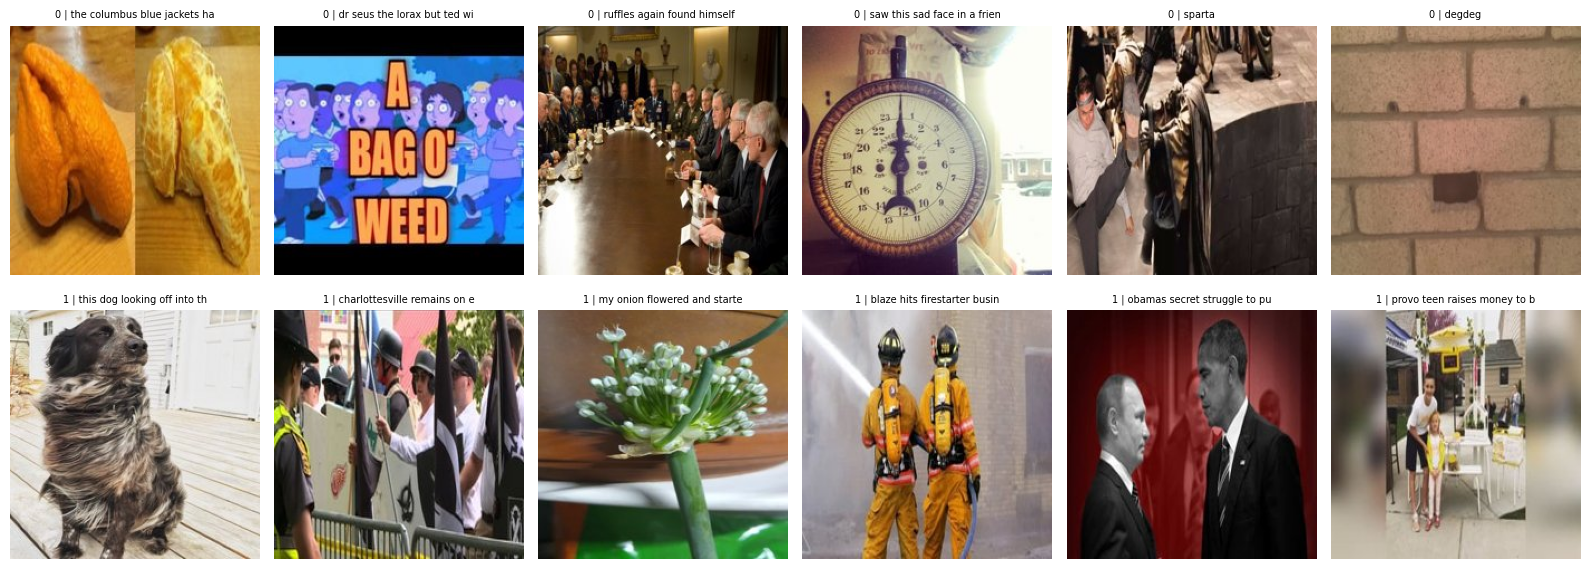

In [7]:
# Cellule 7 : grille d'images, 6 exemples par classe
fig, ax = plt.subplots(2, 6, figsize=(16, 6))
for r, lab in enumerate([0, 1]):
    ech = tr[tr['2_way_label'] == lab].sample(6, random_state=1)
    for c, (_, row) in enumerate(ech.iterrows()):
        ax[r][c].imshow(Image.open(IMG + str(row['id']) + '.jpg'))
        ax[r][c].axis('off')
        ax[r][c].set_title(str(lab) + ' | ' + row['clean_title'][:28], fontsize=7)
plt.tight_layout()
plt.savefig(OUT + 'figures/eda_grille_images.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Cellule 8 : images de remplacement, chiffres de la diapo, et fichiers de sortie (results/ et figures/)
import hashlib, collections, json, time
t0 = time.time()
ids = pd.concat([tr['id'], va['id'], te['id']]).astype(str).tolist()

# 1) Taille de chaque fichier : lecture du catalogue seulement, rapide.
#    (Lire et hacher les 10 231 images peut prendre plusieurs minutes sur un dataset Kaggle monte.)
tailles, manquantes = {}, 0
for k, i in enumerate(ids, 1):
    try:
        tailles[i] = os.path.getsize(IMG + i + '.jpg')
    except OSError:
        manquantes += 1
    if k % 2000 == 0:
        print('  tailles lues : %d / %d (%d s)' % (k, len(ids), time.time() - t0), flush=True)
par_taille = collections.Counter(tailles.values())

# 2) Une image de remplacement est copiee a l identique : ses copies ont toutes la meme taille.
#    On ne lit donc que les fichiers dont la taille est partagee par au moins 20 fichiers.
candidats = [i for i, t in tailles.items() if par_taille[t] >= 20]
cnt = collections.Counter()
for i in candidats:
    with open(IMG + i + '.jpg', 'rb') as f:
        cnt[hashlib.md5(f.read()).hexdigest()] += 1
rempl = sum(n for n in cnt.values() if n >= 20)    # nombre de fichiers qui sont des images de remplacement
print('fichiers images lus pour verification :', len(candidats), 'sur', len(tailles))
print('images de remplacement restantes (>= 20 fichiers identiques) :', rempl, '(attendu : 0 sur la version nettoyee)')
print('images manquantes :', manquantes, '| duree : %d s' % (time.time() - t0))

mots = tr.groupby('2_way_label')['clean_title'].apply(lambda s: s.str.split().str.len().mean()).round(1).to_dict()
print('--- chiffres de la diapo "Quatre constats" a comparer ---')
print('classes equilibrees : tout vrai =', round(te['2_way_label'].mean(), 3), '(diapo : 0,503)')
print('titres : mots par classe (train) =', mots, '(diapo : environ 6 faux, 9 vrai)')
print('sous-reddit = classe : part =', round(pur, 3), '(diapo : environ 100 %)')

# resume complet, a garder dans le projet (results/eda_resume.json)
def periode(d):
    t = pd.to_datetime(d['created_utc'], unit='s')
    return [str(t.min().date()), str(t.max().date())]

resume = dict(
    n=dict(train=len(tr), val=len(va), test=len(te)),
    part_classe1_vrai=dict(train=round(float(tr['2_way_label'].mean()), 4), val=round(float(va['2_way_label'].mean()), 4), test=round(float(te['2_way_label'].mean()), 4)),
    accuracy_tout_vrai_test=round(float(te['2_way_label'].mean()), 4),
    six_way={nm: {int(k): int(v) for k, v in d['6_way_label'].value_counts().sort_index().items()} for nm, d in [('train', tr), ('val', va), ('test', te)]},
    mots_par_titre_train={int(k): float(v) for k, v in mots.items()},
    sous_reddit=dict(nombre_train=int(tr['subreddit'].nunique()), part_classe_majoritaire=round(float(pur), 4),
                     test_absents_du_train=len(set(te['subreddit']) - set(tr['subreddit']))),
    periode=dict(train=periode(tr), val=periode(va), test=periode(te)),
    fuite=dict(titres_communs_train_test=len(set(tr['clean_title']) & set(te['clean_title'])),
               titres_communs_train_val=len(set(tr['clean_title']) & set(va['clean_title'])),
               doublons_train=int(tr['clean_title'].duplicated().sum()),
               ids_communs_train_test=len(set(tr['id']) & set(te['id']))),
    images=dict(plus_grand_groupe_meme_taille=int(max(par_taille.values(), default=0)),
                fichiers_remplacement_restants=int(rempl), fichiers_manquants=int(manquantes)))
with open(OUT + 'results/eda_resume.json', 'w', encoding='utf-8') as f:
    json.dump(resume, f, indent=2, ensure_ascii=False)

print('--- fichiers produits (onglet Output apres Save Version) ---')
for root, _, files in os.walk(OUT):
    for fn in sorted(files):
        print(os.path.join(root, fn), round(os.path.getsize(os.path.join(root, fn)) / 1e6, 2), 'Mo')

  tailles lues : 2000 / 10231 (0 s)
  tailles lues : 4000 / 10231 (0 s)
  tailles lues : 6000 / 10231 (1 s)
  tailles lues : 8000 / 10231 (1 s)
  tailles lues : 10000 / 10231 (2 s)
fichiers images lus pour verification : 0 sur 10231
images de remplacement restantes (>= 20 fichiers identiques) : 0 (attendu : 0 sur la version nettoyee)
images manquantes : 0 | duree : 2 s
--- chiffres de la diapo "Quatre constats" a comparer ---
classes equilibrees : tout vrai = 0.503 (diapo : 0,503)
titres : mots par classe (train) = {0: 6.1, 1: 9.4} (diapo : environ 6 faux, 9 vrai)
sous-reddit = classe : part = 1.0 (diapo : environ 100 %)
--- fichiers produits (onglet Output apres Save Version) ---
/kaggle/working/__notebook__.ipynb 1.65 Mo
/kaggle/working/figures/eda_grille_images.png 2.24 Mo
/kaggle/working/figures/eda_longueur_titres.png 0.02 Mo
/kaggle/working/results/eda_resume.json 0.0 Mo
